# Visualize Inverse Kinemtics 2 link (elbow up)

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import math

init_theta1 = None
init_theta2 = None

## inverse_kinematics_2link

In [30]:
def inverse_kinematics_2link(L1, L2, theta1_min, theta1_max, theta2_min, theta2_max, target_end_effector_pos):
    global init_theta1, init_theta2
    
    x, y = target_end_effector_pos
    
    # Check if y-coordinate is non-negative
    if y < 0:
        return "Error: Y-coordinate must be greater than or equal to 0."

    d2 = x**2 + y**2
    d = np.sqrt(d2)

    base_angle = np.arctan2(y, x)

    # Cosine of the first angle in a triangle defined by L1 and L2
    C = (L1**2 + d2 - L2**2) / (2 * L1 * d)
    c = np.arccos(C)

    # Check if the target is reachable
    if not -1 <= C <= 1:
        return "Error: Target is outside the reachable workspace."

    # Cosine of the second angle
    B = (L1**2 + L2**2 - d2) / (2 * L1 * L2)
    b = np.arccos(B)

    # Calculate joint angles for elbow up configuration
    theta1_elbow_up = base_angle + c
    theta2_elbow_up = b - np.pi

    # Check if elbow up joint angles are within specified limits
    if (theta1_min <= theta1_elbow_up <= theta1_max) and (theta2_min <= theta2_elbow_up <= theta2_max):
        init_theta1 = theta1_elbow_up
        init_theta2 = theta2_elbow_up
        return

    # Calculate joint angles for elbow down configuration
    theta1_elbow_down = base_angle - c
    theta2_elbow_down = np.pi - b

    # Check if elbow down joint angles are within specified limits
    if (theta1_min <= theta1_elbow_down <= theta1_max) and (theta2_min <= theta2_elbow_down <= theta2_max):
        init_theta1 = theta1_elbow_down
        init_theta2 = theta2_elbow_down
        return

    return "Error: No valid joint angles found within the specified limits."

## Plot Function

In [31]:
def plot_manipulator(L1, L2, theta1, theta2):
    # Calculate joint positions
    x1 = L1 * np.cos(theta1)
    y1 = L1 * np.sin(theta1)
    x2 = x1 + L2 * np.cos(theta1 + theta2)
    y2 = y1 + L2 * np.sin(theta1 + theta2)

    # Plot manipulator
    plt.figure(figsize=(8, 6))
    plt.plot([0, x1], [0, y1], 'b-', linewidth=2, label='Link 1')
    plt.plot([x1, x2], [y1, y2], 'r-', linewidth=2, label='Link 2')
    plt.plot(0, 0, 'ko')  # Base
    plt.plot(x1, y1, 'ko')  # Joint 1
    plt.plot(x2, y2, 'ko')  # End effector
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('2-Link Manipulator Configuration')
    plt.axis('equal')
    plt.grid(True)
    plt.legend()
    plt.show()

## Inputs

Joint angles: 0.7072450286871088 -0.5053605102841572


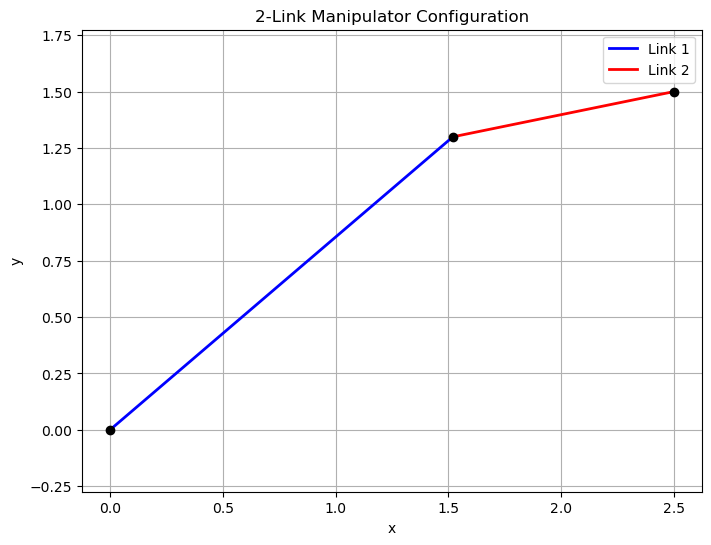

In [40]:
# Example usage

target_pos = (2.5, 1.5)

L1 = 2
L2 = 1

#radians
theta1_min = 0
theta1_max = math.pi/2
theta2_min = -math.pi 
theta2_max = math.pi

result = inverse_kinematics_2link(L1, L2, theta1_min, theta1_max, theta2_min, theta2_max, target_pos)

if isinstance(result, str):
    print(result)
else:
    print("Joint angles:", init_theta1, init_theta2)
    # Plot the manipulator configuration
    plot_manipulator(L1, L2, init_theta1, init_theta2)